In [1]:
import pandas as pd
df=pd.read_csv("Students[1].csv")


In [2]:
df.head()

,Student_Name,College_Name,Stream,Year_of_Study,AI_Tools_Used,Daily_Usage_Hours,Use_Cases,Trust_in_AI_Tools,Impact_on_Grades,Do_Professors_Allow_Use,Preferred_AI_Tool,Awareness_Level,Willing_to_Pay_for_Access,State,Device_Used,Internet_Access
0,Aarav,Indian Institute of Information Technology,Engineering,4,Gemini,0.9,"Assignments, Coding Help",2,2,No,Copilot,9,Yes,Uttar pradesh,Mobile,Poor
1,Vivaan,"Government Ram Bhajan Rai NES College, Jashpur",Commerce,2,ChatGPT,3.4,Learning new topics,3,-3,Yes,Other,6,No,Chhattisgarh,Laptop,Poor
2,Aditya,Dolphin PG Institute of BioMedical & Natural,Science,2,Copilot,3.6,"MCQ Practice, Projects",5,0,No,Gemini,1,No,Uttarakhand,Tablet,Poor
3,Vihaan,Shaheed Rajguru College of Applied Sciences for,Arts,2,Copilot,2.9,Content Writing,5,2,Yes,Gemini,5,No,Delhi ncr,Laptop,High
4,Arjun,Roorkee College of Engineering,Science,1,Gemini,0.9,"Doubt Solving, Resume Writing",1,3,Yes,Other,8,Yes,Uttarakhand,Laptop,Medium


In [3]:
df.shape

(3614, 16)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3614 entries, 0 to 3613
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Student_Name               3614 non-null   object 
 1   College_Name               3614 non-null   object 
 2   Stream                     3614 non-null   object 
 3   Year_of_Study              3614 non-null   int64  
 4   AI_Tools_Used              3614 non-null   object 
 5   Daily_Usage_Hours          3614 non-null   float64
 6   Use_Cases                  3614 non-null   object 
 7   Trust_in_AI_Tools          3614 non-null   int64  
 8   Impact_on_Grades           3614 non-null   int64  
 9   Do_Professors_Allow_Use    3614 non-null   object 
 10  Preferred_AI_Tool          3614 non-null   object 
 11  Awareness_Level            3614 non-null   int64  
 12  Willing_to_Pay_for_Access  3614 non-null   object 
 13  State                      2000 non-null   objec

In [5]:
df.dtypes

Student_Name                  object
College_Name                  object
Stream                        object
Year_of_Study                  int64
AI_Tools_Used                 object
Daily_Usage_Hours            float64
Use_Cases                     object
Trust_in_AI_Tools              int64
Impact_on_Grades               int64
Do_Professors_Allow_Use       object
Preferred_AI_Tool             object
Awareness_Level                int64
Willing_to_Pay_for_Access     object
State                         object
Device_Used                   object
Internet_Access               object
dtype: object

In [ ]:
# Predicting the Impact of AI Tool Usage on Academic Performance among Indian College Students Using Machine Learning"

In [6]:
# Count of missing values
null_count = df.isnull().sum()

# Percentage of missing values
null_percentage = (df.isnull().sum() / df.shape[0]) * 100

# Combine into one DataFrame
null_analysis = pd.DataFrame({
    "Null Count": null_count,
    "Null Percentage": null_percentage
})

print(null_analysis)

                           Null Count  Null Percentage
Student_Name                        0         0.000000
College_Name                        0         0.000000
Stream                              0         0.000000
Year_of_Study                       0         0.000000
AI_Tools_Used                       0         0.000000
Daily_Usage_Hours                   0         0.000000
Use_Cases                           0         0.000000
Trust_in_AI_Tools                   0         0.000000
Impact_on_Grades                    0         0.000000
Do_Professors_Allow_Use             0         0.000000
Preferred_AI_Tool                   0         0.000000
Awareness_Level                     0         0.000000
Willing_to_Pay_for_Access           0         0.000000
State                            1614        44.659657
Device_Used                         0         0.000000
Internet_Access                     0         0.000000


In [7]:
high_null_cols = null_analysis[null_analysis["Null Percentage"] > 20]

print("Columns with more than 20% missing values:")
print(high_null_cols)

Columns with more than 20% missing values:
       Null Count  Null Percentage
State        1614        44.659657


In [8]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [9]:
# Null percentage before removing duplicates
null_before = (df.isnull().sum() / len(df)) * 100

In [10]:
# Store original number of rows
rows_before = len(df)

# Remove duplicates
df = df.drop_duplicates()

# Rows after removal
rows_after = len(df)

# Number of rows removed
rows_removed = rows_before - rows_after

print(f"Rows before removing duplicates: {rows_before}")
print(f"Rows after removing duplicates: {rows_after}")
print(f"Duplicate rows removed: {rows_removed}")

Rows before removing duplicates: 3614
Rows after removing duplicates: 3614
Duplicate rows removed: 0


In [11]:
# Null percentage after removing duplicates
null_after = (df.isnull().sum() / len(df)) * 100

# Comparison
null_comparison = pd.DataFrame({
    "Before (%)": null_before.round(2),
    "After (%)": null_after.round(2)
})

print(null_comparison)

                           Before (%)  After (%)
Student_Name                     0.00       0.00
College_Name                     0.00       0.00
Stream                           0.00       0.00
Year_of_Study                    0.00       0.00
AI_Tools_Used                    0.00       0.00
Daily_Usage_Hours                0.00       0.00
Use_Cases                        0.00       0.00
Trust_in_AI_Tools                0.00       0.00
Impact_on_Grades                 0.00       0.00
Do_Professors_Allow_Use          0.00       0.00
Preferred_AI_Tool                0.00       0.00
Awareness_Level                  0.00       0.00
Willing_to_Pay_for_Access        0.00       0.00
State                           44.66      44.66
Device_Used                      0.00       0.00
Internet_Access                  0.00       0.00


In [12]:
if null_before.round(2).equals(null_after.round(2)):
    print("Duplicate removal did NOT change the null percentage of any column.")
else:
    print("Duplicate removal changed the null percentage of one or more columns.")

Duplicate removal did NOT change the null percentage of any column.


In [13]:
df["Daily_Usage_Hours"] = pd.to_numeric(
    df["Daily_Usage_Hours"],
    errors="coerce"
)

In [14]:
category_cols = [
    "Stream",
    "AI_Tools_Used",
    "Use_Cases",
    "Preferred_AI_Tool",
    "State",
    "Device_Used",
    "Internet_Access",
    "Do_Professors_Allow_Use",
    "Willing_to_Pay_for_Access"
]

In [15]:
memory_before = df.memory_usage(deep=True).sum()

print(f"Memory Before: {memory_before} bytes")

Memory Before: 2466972 bytes


In [16]:
memory_after = df.memory_usage(deep=True).sum()

print(f"Memory After : {memory_after} bytes")

print(f"Memory Saved : {memory_before - memory_after} bytes")

Memory After : 2466972 bytes
Memory Saved : 0 bytes


In [17]:
saving = ((memory_before - memory_after) / memory_before) * 100

print(f"Memory Reduction: {saving:.2f}%")

Memory Reduction: 0.00%


In [18]:
# Descriptive statistics for numeric columns
desc_stats = df.describe()

print(desc_stats)

       Year_of_Study  Daily_Usage_Hours  Trust_in_AI_Tools  Impact_on_Grades  \
count    3614.000000        3614.000000        3614.000000       3614.000000   
mean        2.472883           2.559685           3.023243          0.003320   
std         1.107912           1.213319           1.436934          2.370706   
min         1.000000           0.500000           1.000000         -5.000000   
25%         2.000000           1.500000           2.000000         -2.000000   
50%         2.000000           2.600000           3.000000          0.000000   
75%         3.000000           3.600000           4.000000          2.000000   
max         4.000000           5.000000           5.000000          5.000000   

       Awareness_Level  
count      3614.000000  
mean          5.828445  
std           2.925481  
min           1.000000  
25%           3.000000  
50%           6.000000  
75%           8.000000  
max          10.000000  


In [19]:
# Skewness of all numeric columns
skewness = df.select_dtypes(include=['int64', 'float64']).skew()

print(skewness)


Year_of_Study        0.045889
Daily_Usage_Hours   -0.000296
Trust_in_AI_Tools    0.005766
Impact_on_Grades    -0.024905
Awareness_Level     -0.152830
dtype: float64


In [20]:
# Column with highest absolute skewness
highest_skew_col = skewness.abs().idxmax()
highest_skew_value = skewness[highest_skew_col]

print(f"Column with highest absolute skewness: {highest_skew_col}")
print(f"Skewness value: {highest_skew_value:.4f}")

Column with highest absolute skewness: Awareness_Level
Skewness value: -0.1528


In [21]:
skew_df = skewness.reset_index()
skew_df.columns = ["Column", "Skewness"]

print(skew_df)

              Column  Skewness
0      Year_of_Study  0.045889
1  Daily_Usage_Hours -0.000296
2  Trust_in_AI_Tools  0.005766
3   Impact_on_Grades -0.024905
4    Awareness_Level -0.152830


In [22]:
def detect_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nColumn : {col}")
    print(f"Q1            : {Q1}")
    print(f"Q3            : {Q3}")
    print(f"IQR           : {IQR}")
    print(f"Lower Bound   : {lower}")
    print(f"Upper Bound   : {upper}")
    print(f"Outlier Count : {len(outliers)}")

    return outliers

In [23]:
outliers_daily = detect_outliers_iqr(df, "Daily_Usage_Hours")

outliers_trust = detect_outliers_iqr(df, "Trust_in_AI_Tools")


Column : Daily_Usage_Hours
Q1            : 1.5
Q3            : 3.6
IQR           : 2.1
Lower Bound   : -1.6500000000000004
Upper Bound   : 6.75
Outlier Count : 0

Column : Trust_in_AI_Tools
Q1            : 2.0
Q3            : 4.0
IQR           : 2.0
Lower Bound   : -1.0
Upper Bound   : 7.0
Outlier Count : 0


In [24]:
columns = ["Daily_Usage_Hours", "Trust_in_AI_Tools"]

summary = []

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    summary.append([col, Q1, Q3, IQR, lower, upper, count])

import pandas as pd

summary_df = pd.DataFrame(summary,
                          columns=[
                              "Column",
                              "Q1",
                              "Q3",
                              "IQR",
                              "Lower Bound",
                              "Upper Bound",
                              "Outlier Count"
                          ])

print(summary_df)

              Column   Q1   Q3  IQR  Lower Bound  Upper Bound  Outlier Count
0  Daily_Usage_Hours  1.5  3.6  2.1        -1.65         6.75              0
1  Trust_in_AI_Tools  2.0  4.0  2.0        -1.00         7.00              0


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

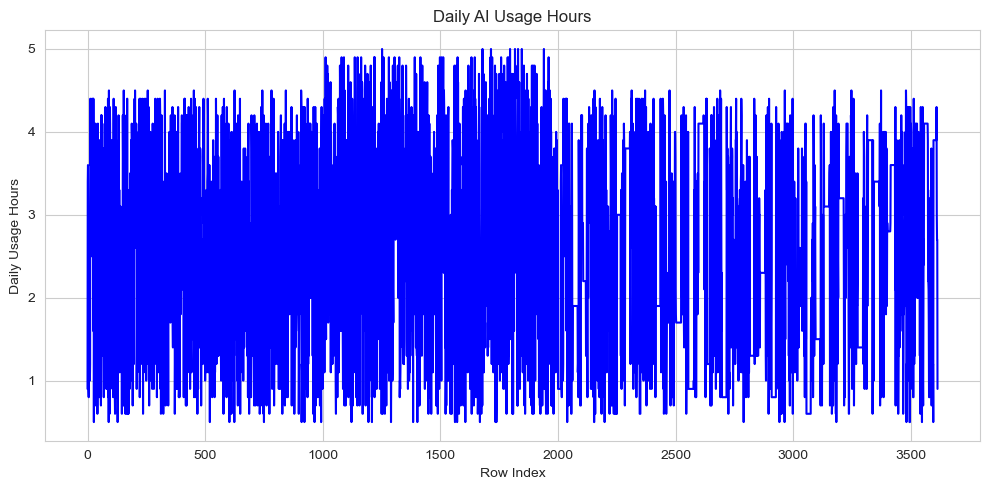

In [26]:
plt.figure(figsize=(10,5))

plt.plot(df.index, df["Daily_Usage_Hours"], color="blue")

plt.title("Daily AI Usage Hours")
plt.xlabel("Row Index")
plt.ylabel("Daily Usage Hours")

plt.tight_layout()
plt.savefig("plots/line_plot_daily_usage.png", dpi=300)

plt.show()

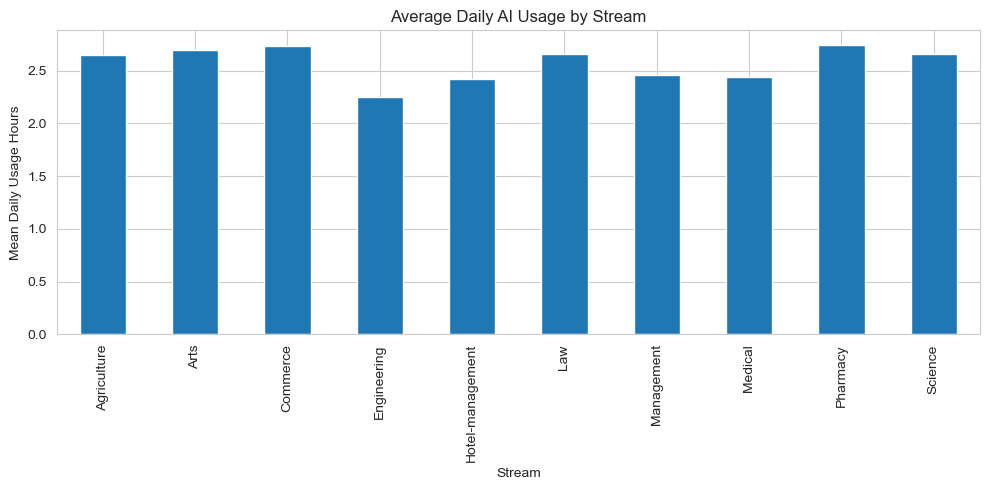

In [27]:
plt.figure(figsize=(10,5))

df.groupby("Stream")["Daily_Usage_Hours"].mean().plot.bar()

plt.title("Average Daily AI Usage by Stream")
plt.xlabel("Stream")
plt.ylabel("Mean Daily Usage Hours")

plt.tight_layout()
plt.savefig("plots/bar_chart_stream_usage.png", dpi=300)

plt.show()

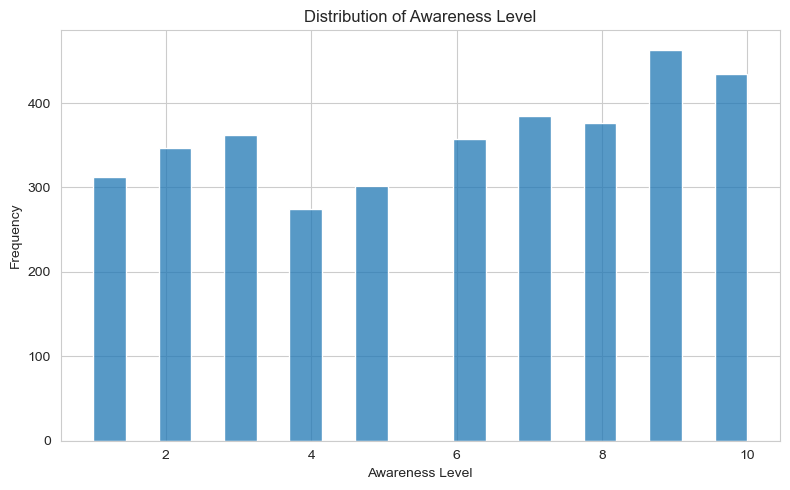

In [28]:
plt.figure(figsize=(8,5))

sns.histplot(df["Awareness_Level"], bins=20)

plt.title("Distribution of Awareness Level")
plt.xlabel("Awareness Level")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("plots/histogram_awareness_level.png", dpi=300)

plt.show()

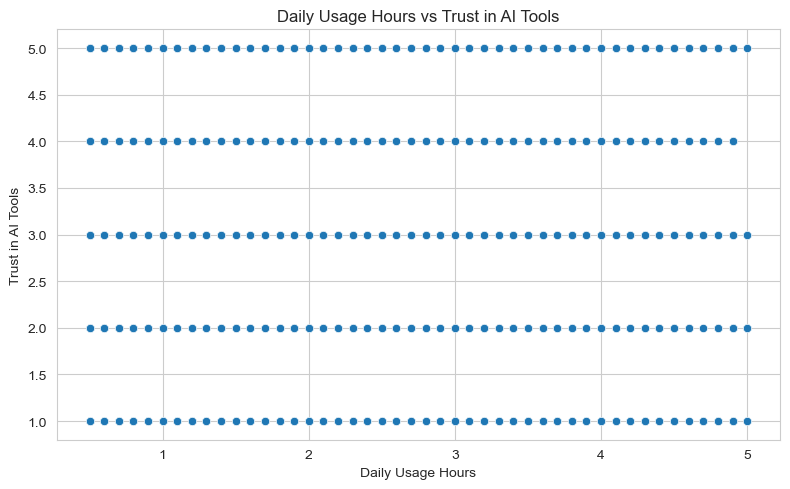

In [29]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x="Daily_Usage_Hours",
    y="Trust_in_AI_Tools",
    data=df
)

plt.title("Daily Usage Hours vs Trust in AI Tools")
plt.xlabel("Daily Usage Hours")
plt.ylabel("Trust in AI Tools")

plt.tight_layout()
plt.savefig("plots/scatter_usage_trust.png", dpi=300)

plt.show()

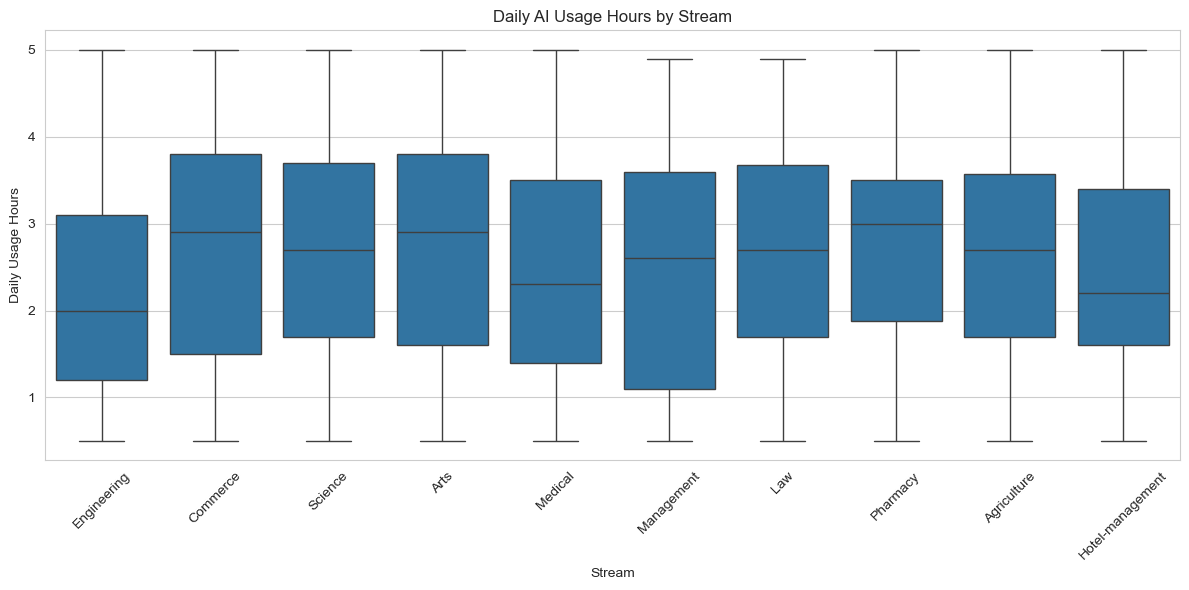

In [30]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x="Stream",
    y="Daily_Usage_Hours",
    data=df
)

plt.title("Daily AI Usage Hours by Stream")
plt.xlabel("Stream")
plt.ylabel("Daily Usage Hours")

plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("plots/boxplot_stream_usage.png", dpi=300)

plt.show()

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix
corr_matrix = df.select_dtypes(include=['int64', 'float64']).corr()

print(corr_matrix)

                   Year_of_Study  Daily_Usage_Hours  Trust_in_AI_Tools  \
Year_of_Study           1.000000           0.007906           0.000744   
Daily_Usage_Hours       0.007906           1.000000          -0.012369   
Trust_in_AI_Tools       0.000744          -0.012369           1.000000   
Impact_on_Grades       -0.005867           0.057222          -0.047310   
Awareness_Level        -0.012708           0.005981           0.039466   

                   Impact_on_Grades  Awareness_Level  
Year_of_Study             -0.005867        -0.012708  
Daily_Usage_Hours          0.057222         0.005981  
Trust_in_AI_Tools         -0.047310         0.039466  
Impact_on_Grades           1.000000        -0.015721  
Awareness_Level           -0.015721         1.000000  


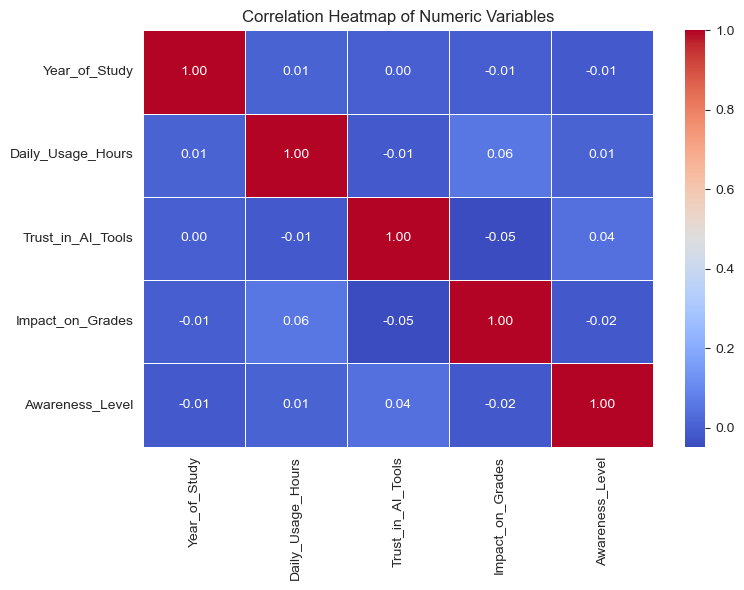

In [32]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numeric Variables")

plt.tight_layout()

plt.savefig("plots/correlation_heatmap.png", dpi=300)

plt.show()

In [33]:
import numpy as np

# Remove self-correlations (diagonal)
corr_abs = corr_matrix.abs()

np.fill_diagonal(corr_abs.values, 0)

# Find highest absolute correlation
max_corr = corr_abs.unstack().idxmax()
max_value = corr_abs.unstack().max()

print("Highest Correlation Pair:", max_corr)
print("Correlation Value:", max_value)

Highest Correlation Pair: ('Daily_Usage_Hours', 'Impact_on_Grades')
Correlation Value: 0.05722228740958585


In [34]:
# Top 2 skewed numeric columns
cols = ["Awareness_Level", "Year_of_Study"]

comparison = []

for col in cols:
    comparison.append({
        "Column": col,
        "Mean": df[col].mean(),
        "Median": df[col].median(),
        "Skewness": df[col].skew()
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df)

            Column      Mean  Median  Skewness
0  Awareness_Level  5.828445     6.0 -0.152830
1    Year_of_Study  2.472883     2.0  0.045889


In [35]:
for col in cols:
    df[col] = df[col].fillna(df[col].median())

In [36]:
print(df[cols].isnull().sum())

Awareness_Level    0
Year_of_Study      0
dtype: int64


In [38]:
# Pearson correlation matrix
pearson_corr = df.select_dtypes(include=['int64', 'float64']).corr(method='pearson')

print("Pearson Correlation Matrix")
print(pearson_corr)

Pearson Correlation Matrix
                   Year_of_Study  Daily_Usage_Hours  Trust_in_AI_Tools  \
Year_of_Study           1.000000           0.007906           0.000744   
Daily_Usage_Hours       0.007906           1.000000          -0.012369   
Trust_in_AI_Tools       0.000744          -0.012369           1.000000   
Impact_on_Grades       -0.005867           0.057222          -0.047310   
Awareness_Level        -0.012708           0.005981           0.039466   

                   Impact_on_Grades  Awareness_Level  
Year_of_Study             -0.005867        -0.012708  
Daily_Usage_Hours          0.057222         0.005981  
Trust_in_AI_Tools         -0.047310         0.039466  
Impact_on_Grades           1.000000        -0.015721  
Awareness_Level           -0.015721         1.000000  


In [39]:
# Spearman correlation matrix
spearman_corr = df.select_dtypes(include=['int64', 'float64']).corr(method='spearman')

print("Spearman Correlation Matrix")
print(spearman_corr)

Spearman Correlation Matrix
                   Year_of_Study  Daily_Usage_Hours  Trust_in_AI_Tools  \
Year_of_Study           1.000000           0.008156           0.001444   
Daily_Usage_Hours       0.008156           1.000000          -0.012042   
Trust_in_AI_Tools       0.001444          -0.012042           1.000000   
Impact_on_Grades       -0.007906           0.057789          -0.051877   
Awareness_Level        -0.013010           0.004081           0.037371   

                   Impact_on_Grades  Awareness_Level  
Year_of_Study             -0.007906        -0.013010  
Daily_Usage_Hours          0.057789         0.004081  
Trust_in_AI_Tools         -0.051877         0.037371  
Impact_on_Grades           1.000000        -0.014998  
Awareness_Level           -0.014998         1.000000  


In [40]:
import pandas as pd
import numpy as np

numeric_cols = pearson_corr.columns

difference = []

for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):

        p = pearson_corr.iloc[i, j]
        s = spearman_corr.iloc[i, j]

        difference.append([
            numeric_cols[i],
            numeric_cols[j],
            p,
            s,
            abs(s - p)
        ])

difference_df = pd.DataFrame(
    difference,
    columns=[
        "Column 1",
        "Column 2",
        "Pearson",
        "Spearman",
        "|Spearman-Pearson|"
    ]
)

difference_df = difference_df.sort_values(
    "|Spearman-Pearson|",
    ascending=False
)

print(difference_df)

            Column 1           Column 2   Pearson  Spearman  \
7  Trust_in_AI_Tools   Impact_on_Grades -0.047310 -0.051877   
8  Trust_in_AI_Tools    Awareness_Level  0.039466  0.037371   
2      Year_of_Study   Impact_on_Grades -0.005867 -0.007906   
6  Daily_Usage_Hours    Awareness_Level  0.005981  0.004081   
9   Impact_on_Grades    Awareness_Level -0.015721 -0.014998   
1      Year_of_Study  Trust_in_AI_Tools  0.000744  0.001444   
5  Daily_Usage_Hours   Impact_on_Grades  0.057222  0.057789   
4  Daily_Usage_Hours  Trust_in_AI_Tools -0.012369 -0.012042   
3      Year_of_Study    Awareness_Level -0.012708 -0.013010   
0      Year_of_Study  Daily_Usage_Hours  0.007906  0.008156   

   |Spearman-Pearson|  
7            0.004567  
8            0.002095  
2            0.002039  
6            0.001900  
9            0.000723  
1            0.000700  
5            0.000567  
4            0.000327  
3            0.000302  
0            0.000250  


In [41]:
top3 = difference_df.head(3)

print(top3)

            Column 1          Column 2   Pearson  Spearman  |Spearman-Pearson|
7  Trust_in_AI_Tools  Impact_on_Grades -0.047310 -0.051877            0.004567
8  Trust_in_AI_Tools   Awareness_Level  0.039466  0.037371            0.002095
2      Year_of_Study  Impact_on_Grades -0.005867 -0.007906            0.002039


In [42]:
categorical_col = "Stream"
numeric_col = "Daily_Usage_Hours"

group_stats = (
    df.groupby(categorical_col)[numeric_col]
      .agg(['mean', 'std', 'count'])
)

print(group_stats)

                      mean       std  count
Stream                                     
Agriculture       2.651908  1.170247    262
Arts              2.699516  1.233493    413
Commerce          2.733242  1.260578    364
Engineering       2.245545  1.168207    505
Hotel-management  2.419811  1.155600    318
Law               2.658130  1.164051    246
Management        2.456316  1.327500    380
Medical           2.438790  1.215300    281
Pharmacy          2.744048  1.142934    252
Science           2.661889  1.164406    593


In [43]:
highest_mean_group = group_stats["mean"].idxmax()
highest_mean_value = group_stats["mean"].max()

highest_std_group = group_stats["std"].idxmax()
highest_std_value = group_stats["std"].max()

print("Highest Mean Group :", highest_mean_group)
print("Highest Mean Value :", highest_mean_value)

print("Highest Std Group  :", highest_std_group)
print("Highest Std Value  :", highest_std_value)

Highest Mean Group : Pharmacy
Highest Mean Value : 2.744047619047619
Highest Std Group  : Management
Highest Std Value  : 1.3274997250721587


In [44]:
highest_mean = group_stats["mean"].max()
lowest_mean = group_stats["mean"].min()

ratio = highest_mean / lowest_mean

print("Highest Mean :", highest_mean)
print("Lowest Mean  :", lowest_mean)
print("Mean Ratio   :", ratio)

Highest Mean : 2.744047619047619
Lowest Mean  : 2.2455445544554458
Mean Ratio   : 1.2219965146552447


In [45]:
print(group_stats.sort_values("mean", ascending=False))

                      mean       std  count
Stream                                     
Pharmacy          2.744048  1.142934    252
Commerce          2.733242  1.260578    364
Arts              2.699516  1.233493    413
Science           2.661889  1.164406    593
Law               2.658130  1.164051    246
Agriculture       2.651908  1.170247    262
Management        2.456316  1.327500    380
Medical           2.438790  1.215300    281
Hotel-management  2.419811  1.155600    318
Engineering       2.245545  1.168207    505


In [46]:
print(group_stats)

                      mean       std  count
Stream                                     
Agriculture       2.651908  1.170247    262
Arts              2.699516  1.233493    413
Commerce          2.733242  1.260578    364
Engineering       2.245545  1.168207    505
Hotel-management  2.419811  1.155600    318
Law               2.658130  1.164051    246
Management        2.456316  1.327500    380
Medical           2.438790  1.215300    281
Pharmacy          2.744048  1.142934    252
Science           2.661889  1.164406    593
